In [1]:
#Paso 0 - Preparativos

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import scipy.stats as sps
import matplotlib

# Estética
sns.set(style="whitegrid")

In [2]:
# Carga de Dataset

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

# Ver columnas disponibles
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [15]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
# PARTE 1: Best-Seller por categoría
# Objetivo: ¿Hay categorías con más best-sellers?

In [4]:
## Crosstab entre category y isBestSeller:

crosstab = pd.crosstab(df['category'], df['isBestSeller'], normalize='index')  # proporción por categoría
crosstab_sorted = crosstab.sort_values(True, ascending=False)  # orden descendente por best-seller
crosstab_sorted.head(10)

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
"Billiard, Snooker & Pool",0.967871,0.032129
Pet Supplies,0.969800,0.030200
Home Brewing & Wine Making,0.971545,0.028455
Wind Instruments,0.972000,0.028000


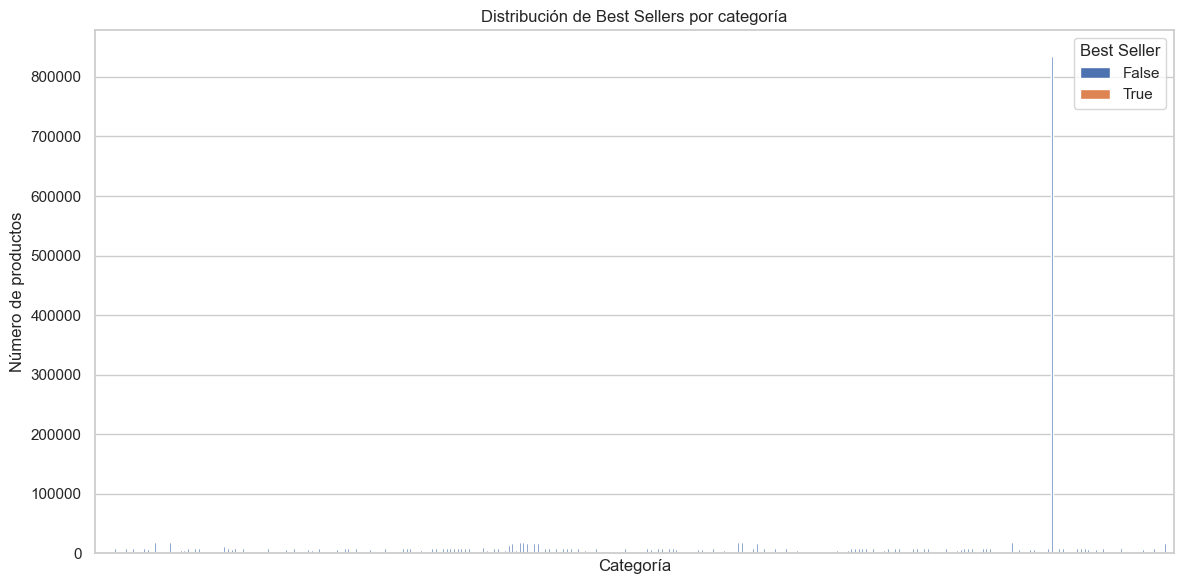

In [5]:
## Gráfico de barras apiladas (stacked bar):

crosstab_raw = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_raw.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.title('Distribución de Best Sellers por categoría')
plt.ylabel('Número de productos')
plt.xlabel('Categoría')
plt.xticks([])
plt.legend(title="Best Seller")
plt.tight_layout()
plt.show()

In [6]:
## Chi-cuadrado y Cramér's V:

# Test de independencia
chi2_result = sps.chi2_contingency(crosstab_raw)
chi2_val, p_val, dof, expected = chi2_result
print("Chi2 =", chi2_val, "| p-valor =", p_val)

# Cramér's V
def cramers_v(confusion_matrix):
    chi2 = sps.chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    return np.sqrt(phi2 / min(k-1, r-1))

cramers_v_score = cramers_v(crosstab_raw)
print("Cramér's V =", round(cramers_v_score, 3))

Chi2 = 36540.20270061387 | p-valor = 0.0
Cramér's V = 0.122


In [ ]:
# PARTE 2: Precio y rating según categoría y marca
# Objetivo: ¿Cómo varía el precio/rating por categoría o marca?

In [7]:
## 🧹 Eliminar outliers por precio (IQR method)

Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_clean = df[(df['price'] >= lower) & (df['price'] <= upper)]

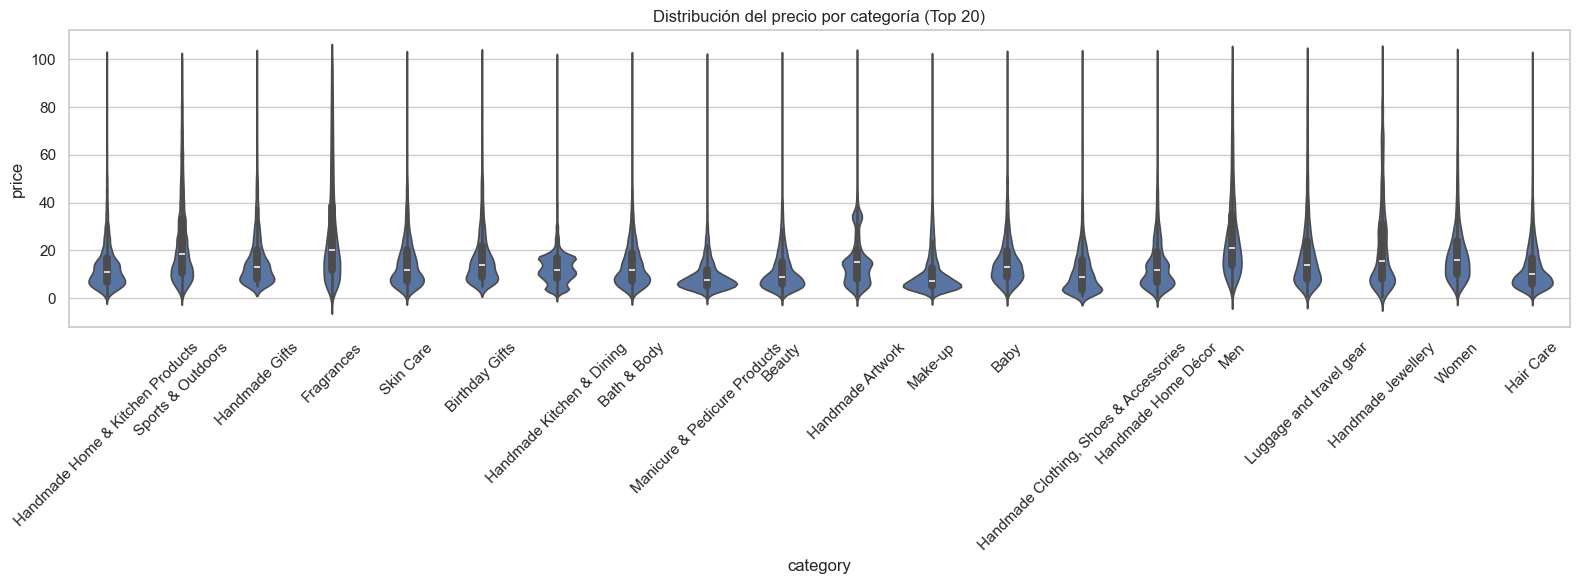

In [8]:
## Violin plot de precio por categoría (top 20)

top20 = df_clean['category'].value_counts().head(20).index
plt.figure(figsize=(16, 6))
sns.violinplot(data=df_clean[df_clean['category'].isin(top20)],
               x='category', y='price')
plt.xticks(rotation=45)
plt.title("Distribución del precio por categoría (Top 20)")
plt.tight_layout()
plt.show()

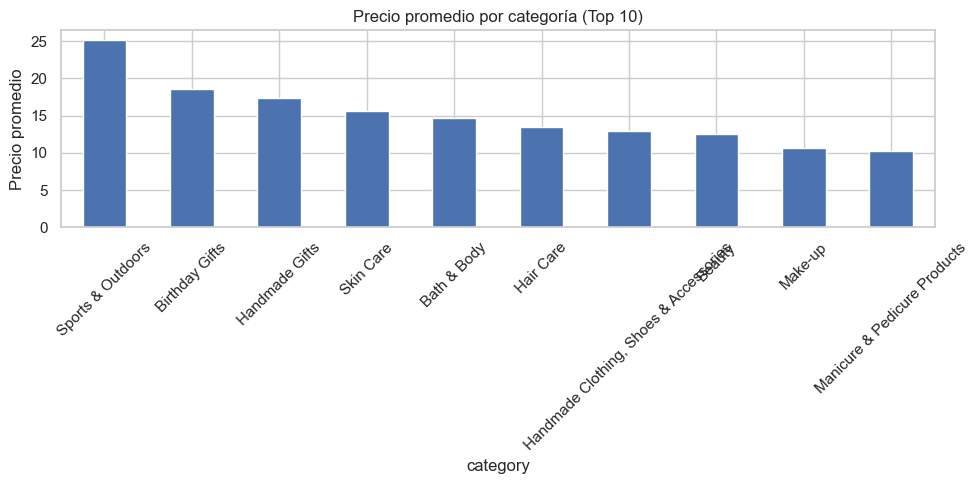

In [9]:
## Bar chart: precio medio por categoría (top 10 por recuento)

top10 = df_clean['category'].value_counts().head(10).index
avg_prices = df_clean[df_clean['category'].isin(top10)].groupby('category')['price'].mean().sort_values(ascending=False)

avg_prices.plot(kind='bar', figsize=(10,5), title='Precio promedio por categoría (Top 10)')
plt.ylabel("Precio promedio")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

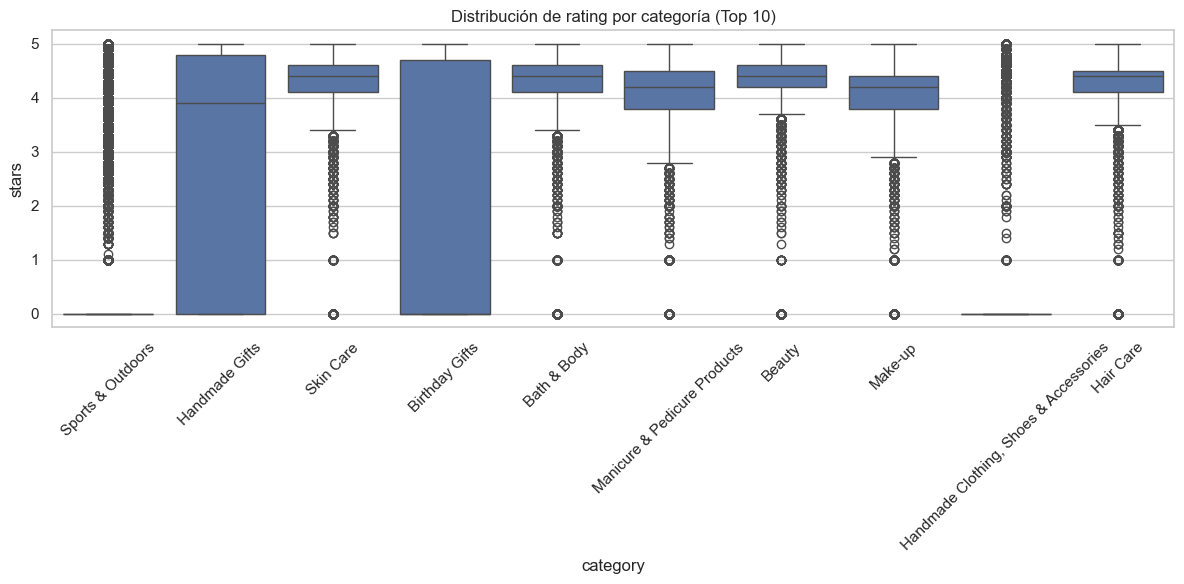

In [11]:
## Boxplot de rating por categoría (top 10)

top10_cat = df_clean['category'].value_counts().head(10).index
plt.figure(figsize=(12,6))
sns.boxplot(data=df_clean[df_clean['category'].isin(top10_cat)],
            x='category', y='stars')
plt.title('Distribución de rating por categoría (Top 10)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# PARTE 3: Relación entre precio y rating

In [16]:
## Correlación

corr = df_clean[['price', 'stars']].corr()
print("Correlación precio-rating:", round(corr.loc['price', 'stars'], 3))

Correlación precio-rating: -0.078


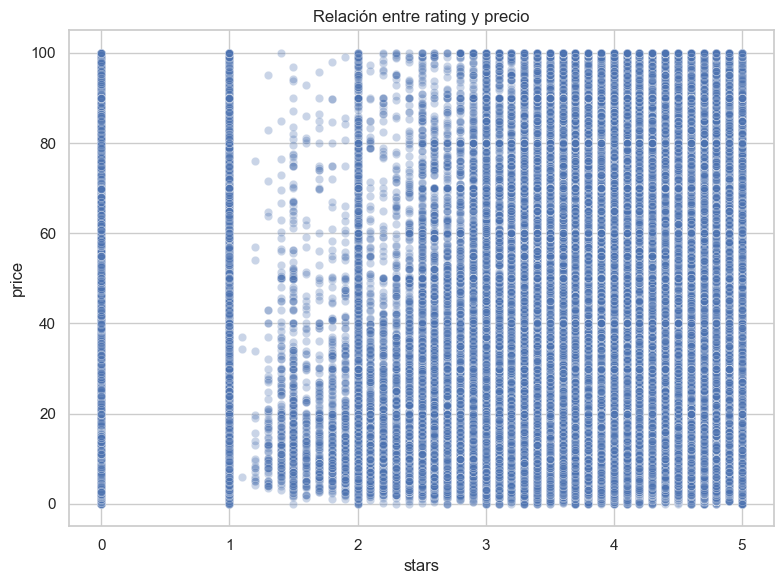

In [18]:
## Scatterplot precio vs rating

plt.figure(figsize=(8,6))
sns.scatterplot(data=df_clean, x='stars', y='price', alpha=0.3)
plt.title("Relación entre rating y precio")
plt.tight_layout()
plt.show()

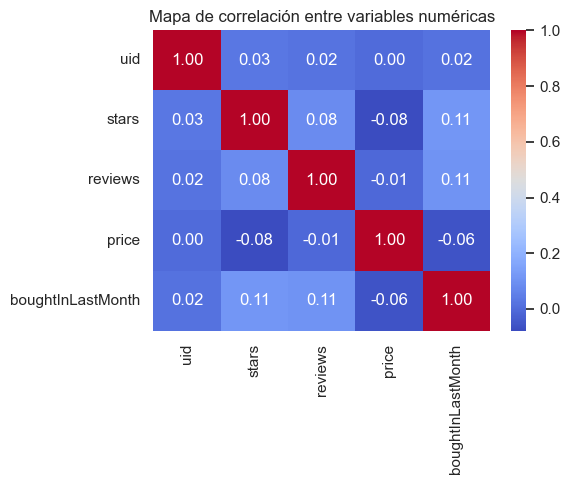

In [22]:
## Heatmap de correlaciones

# Solo columnas numéricas
num_df = df_clean.select_dtypes(include='number')

plt.figure(figsize=(6, 5))
sns.heatmap(num_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Mapa de correlación entre variables numéricas")
plt.tight_layout()
plt.show()